<a href="https://colab.research.google.com/github/Ashishkushwaha30/Backend/blob/master/Module3/assignments/gradient_descent_assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab Assignment: Gradient Descent for Polynomial Regression

**Objective:**  
In this lab assignment, you will implement and explore gradient descent for polynomial regression. You will work with synthetic data to fit a polynomial model, compute the loss and gradients, and visualize the results. The goal is to understand the gradient descent algorithm, its application to polynomial regression, and how to evaluate the model's performance.

**Instructions:**  
- Complete the tasks outlined below. Replace `???` placeholders with the correct code.
- Run each cell to verify your implementation.
- Submit this notebook with your solutions and visualizations.
- Do not modify the provided plotting code unless instructed.
  

## Tasks Overview
1. Complete the `predict_poly` function to compute polynomial predictions.
2. Implement the `loss_function_poly` to calculate the Mean Squared Error (MSE).
3. Compute the gradient of the loss function in `gradient_poly`.
4. Run gradient descent and analyze the results.
5. Answer the analysis questions at the end.

In [7]:
# Import libraries
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Set matplotlib to inline for Jupyter notebooks
%matplotlib inline

# Set random seed for reproducibility
np.random.seed(42)

## Task 1: Polynomial Prediction Function

Complete the `predict_poly` function to compute predictions for a polynomial of degree `degree` with coefficients `w` for input features `X`. The function should compute:  
$$ y_{\text{pred}} = w_0 + w_1 x + w_2 x^2 + \dots + w_{\text{degree}} x^{\text{degree}} $$

**Hint:** Use a loop or list comprehension to compute the sum of `$w[j] * X**j$` for `$j$` from 0 to `degree`.

In [8]:
def predict_poly(X, w, degree):
    """
    Compute polynomial predictions for input X.
    X: 1D numpy array of input features
    w: coefficients (numpy array of length degree+1)
    degree: degree of the polynomial
    Returns: predicted y values (numpy array)
    """
    # TODO: Complete the function
    y_pred = 0
    for j in range(degree + 1):
        y_pred += w[j] * X**j
    return y_pred

## Task 2: Loss Function

Implement the `loss_function_poly` to compute the Mean Squared Error (MSE) loss:  
\[ \text{MSE} = \frac{1}{n} \sum_{i=1}^n (y_i - y_{\text{pred},i})^2 \]

**Hint:** Use `predict_poly` to compute `y_pred`, then calculate the mean of squared differences between `y` and `y_pred`.

In [9]:
def loss_function_poly(w, X, y, degree):
    """
    Compute Mean Squared Error loss for polynomial regression.
    w: coefficients
    X: input features
    y: true target values
    degree: degree of the polynomial
    Returns: mean squared error (float)
    """
    # TODO: Complete the function
    y_pred = predict_poly(X, w, degree)
    mse = np.mean((y - y_pred)**2)
    return mse

## Task 3: Gradient of the Loss Function

Complete the `gradient_poly` function to compute the gradient of the MSE loss with respect to each coefficient `w_j`. The gradient for coefficient `w_j` is:  
\[ \frac{\partial \text{MSE}}{\partial w_j} = -\frac{2}{n} \sum_{i=1}^n (y_i - y_{\text{pred},i}) \cdot x_i^j \]

**Hint:** Compute `y_pred` using `predict_poly`, then calculate the gradient for each `j` from 0 to `degree`.

In [10]:
def gradient_poly(w, X, y, degree):
    """
    Compute gradient of the loss function w.r.t. each coefficient.
    Returns: numpy array of gradients (length degree+1)
    """
    # TODO: Complete the function
    y_pred = predict_poly(X, w, degree)
    n = len(X)
    grads = np.array([-2 * np.sum((y - y_pred) * X**j) / n for j in range(degree + 1)])
    return grads

## Task 4: Gradient Descent Implementation

The `gradient_descent_poly` function is provided to perform gradient descent. It initializes coefficients to zero, updates them using the gradient, and tracks the loss and coefficients over iterations. Run this cell to ensure it works with your implementations above.

**Parameters to use:**
- Learning rate: 0.01
- Iterations: 1000
- Degree: 3

In [11]:
def gradient_descent_poly(X, y, learning_rate, iterations, degree):
    """
    Perform gradient descent to fit a polynomial regression model.
    X: input features (numpy array)
    y: target values (numpy array)
    learning_rate: step size for updates
    iterations: number of iterations
    degree: degree of the polynomial
    Returns: DataFrame with columns for iteration, loss, and all coefficients
    """
    w = np.zeros(degree + 1)  # Initialize all coefficients to zero
    history = {
        'iteration': [],
        'loss': [],
        **{f'w{j}': [] for j in range(degree + 1)}
    }
    for i in range(iterations):
        grads = gradient_poly(w, X, y, degree)
        w -= learning_rate * grads
        loss = loss_function_poly(w, X, y, degree)
        history['iteration'].append(i + 1)
        history['loss'].append(loss)
        for j in range(degree + 1):
            history[f'w{j}'].append(w[j])
    return pd.DataFrame(history), w

# Generate synthetic data
np.random.seed(42)
w_true = [1, -1, 2.1, -2]
degree = 3
n = 1000
X = np.random.normal(0, 1, n)
y = sum(w * (X ** j) for j, w in enumerate(w_true)) + np.random.normal(0, np.sqrt(3), n)

# Run gradient descent
learning_rate = 0.01
iterations = 1000
history, final_coeffs = gradient_descent_poly(X, y, learning_rate, iterations, degree)

print(f"True coefficients: {w_true}")
print(f"Learned coefficients: {final_coeffs}")

True coefficients: [1, -1, 2.1, -2]
Learned coefficients: [ 1.09299782 -1.11057523  2.13117852 -1.98824234]


## Task 5: Visualize Results

Run the following cell to visualize the results of your gradient descent implementation. The plots show:
1. The synthetic data points and the fitted polynomial curve.
2. The loss function over iterations.
3. The convergence of the coefficients compared to their true values.

**Do not modify this cell.**

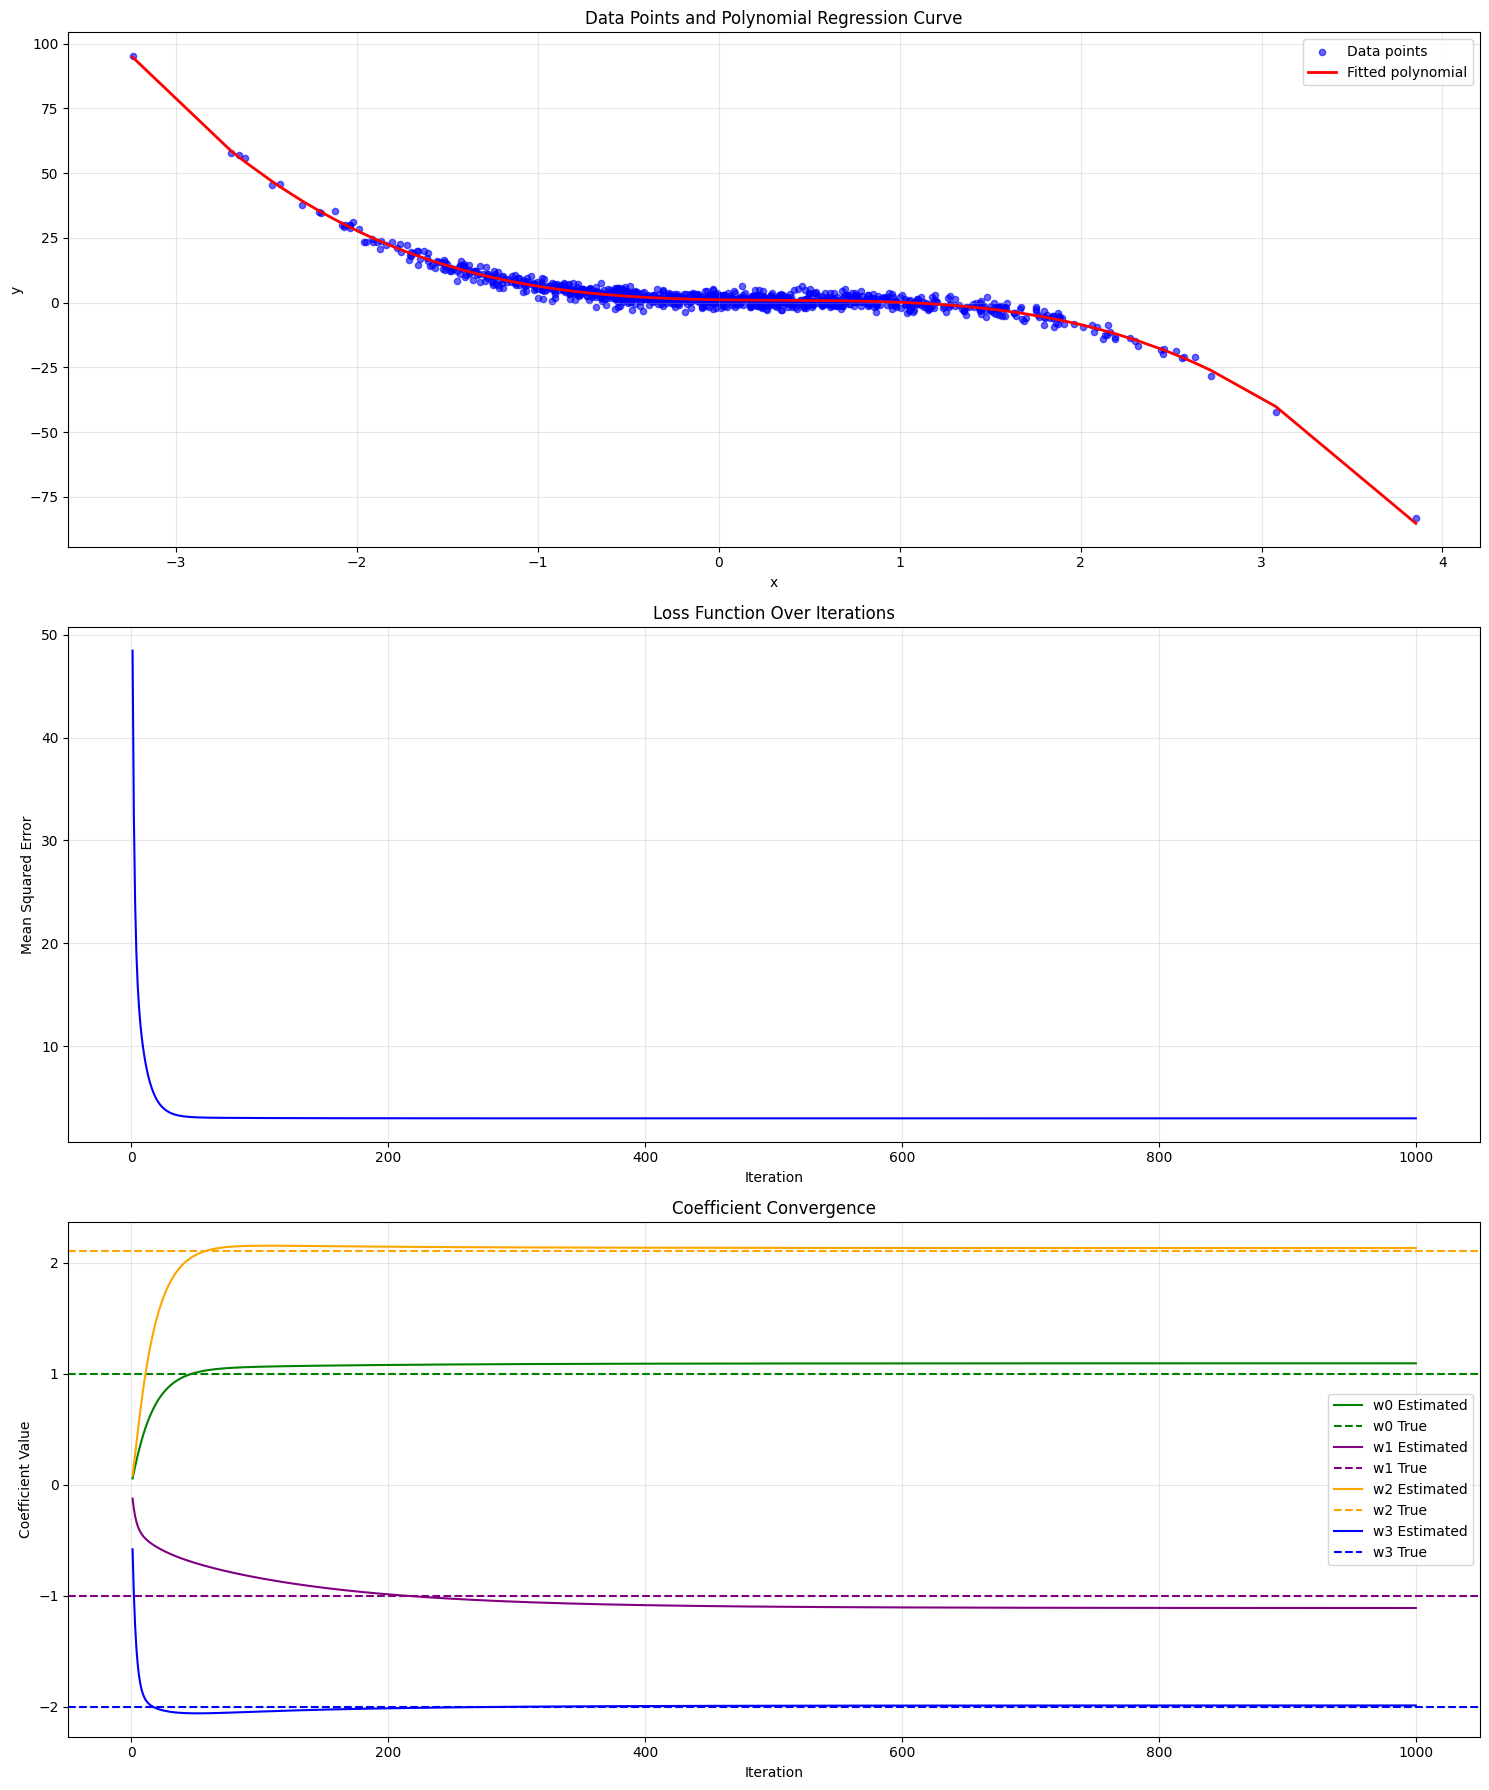

In [12]:
# Create a figure with 3 vertically stacked subplots
fig = plt.figure(figsize=(15, 18))

# Plot 1: Data points and regression curve
plt.subplot(3, 1, 1)
plt.scatter(X, y, alpha=0.6, color='blue', s=20, label='Data points')
X_sorted = np.sort(X)
y_pred = predict_poly(X_sorted, final_coeffs, degree)
plt.plot(X_sorted, y_pred, color='red', linewidth=2, label='Fitted polynomial')
plt.title('Data Points and Polynomial Regression Curve')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.grid(True, alpha=0.3)

# Plot 2: Loss function over iterations
plt.subplot(3, 1, 2)
plt.plot(history['iteration'], history['loss'], color='blue')
plt.title('Loss Function Over Iterations')
plt.xlabel('Iteration')
plt.ylabel('Mean Squared Error')
plt.grid(True, alpha=0.3)

# Plot 3: Coefficient convergence
plt.subplot(3, 1, 3)
colors = ['green', 'purple', 'orange', 'blue']
for j in range(degree + 1):
    plt.plot(history['iteration'], history[f'w{j}'], color=colors[j], label=f'w{j} Estimated')
    plt.axhline(w_true[j], color=colors[j], linestyle='--', label=f'w{j} True')
plt.title('Coefficient Convergence')
plt.xlabel('Iteration')
plt.ylabel('Coefficient Value')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Task 6: Analysis Questions

Answer the following questions based on your implementation and the visualizations. Provide your answers in the markdown cell below.

1. **Convergence of Coefficients:** Did the coefficients converge to the true values (`w_true = [1, -1, 2.1, -2]`) after 1000 iterations? If not, what might be the reasons?
2. **Loss Function Behavior:** Describe the behavior of the loss function over iterations. Does it decrease steadily, or are there fluctuations? What does this suggest about the learning rate?
3. **Model Fit:** Based on the scatter plot and fitted polynomial curve, does the model appear to fit the data well? Why or why not?
4. **Improvements:** Suggest one or two modifications to the gradient descent algorithm (e.g., learning rate, number of iterations) that might improve convergence or model performance.

**Your Answers:**

1. **Convergence of Coefficients:** [Your answer here]
2. **Loss Function Behavior:** [Your answer here]
3. **Model Fit:** [Your answer here]
4. **Improvements:** [Your answer here]